# Project 1 — Bank Marketing: Predicting Term-Deposit Subscription

In [1]:
# Importing packages
import os
# Windows 11 fix: joblib counts CPU cores with the 'wmic' tool, which Windows 11 removed.
# Giving it the core count up front stops the (harmless) warning and traceback.
try:
    from joblib.externals.loky.backend import context as _loky_context
    if _loky_context.physical_cores_cache is None:
        _loky_context.physical_cores_cache = os.cpu_count() or 1
except Exception:
    pass
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = "C:/Users/Irenenm/Desktop/masters2025/YR 2 SEM 11/Data Mining/bank-additional-full.csv" 


In [2]:
raw = pd.read_csv(DATA_PATH, sep=";")
raw["y"] = (raw["y"] == "yes").astype(int)          # 1 = subscribed, 0 = did not
raw["row_order"] = np.arange(len(raw))               # file order is chronological (May 2008 - Nov 2010)
print("Shape:", raw.shape)
raw.head()

Shape: (41188, 22)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,row_order
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,3
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,4


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## 2. Exploratory data analysis

### 2.1 Target variable, duplicates and missing values

Exact duplicate rows: 12
Explicit NaN values: 0


,count,share
y,,
no,36548,0.8873
yes,4640,0.1127


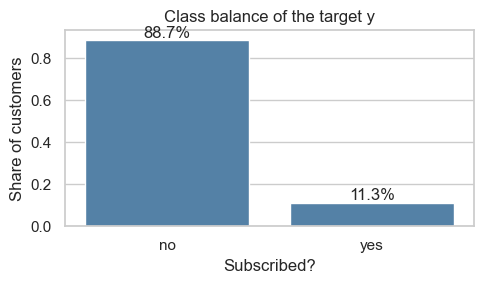

In [4]:
n_dup = raw.drop(columns="row_order").duplicated().sum()
print(f"Exact duplicate rows: {n_dup}")
print(f"Explicit NaN values: {raw.isna().sum().sum()}")

target = raw["y"].value_counts().rename(index={0: "no", 1: "yes"}).to_frame("count")
target["share"] = target["count"] / target["count"].sum()
display(target)

fig, ax = plt.subplots(figsize=(5, 3))
sns.barplot(x=target.index, y=target["share"], ax=ax, color="steelblue")
ax.set(title="Class balance of the target y", ylabel="Share of customers", xlabel="Subscribed?")
for i, v in enumerate(target["share"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.tight_layout(); plt.show()

In [5]:
cat_raw = [c for c in raw.columns if raw[c].dtype.kind not in "biuf"]
unknown = pd.DataFrame({
    "n_unknown": [(raw[c] == "unknown").sum() for c in cat_raw],
    "pct_unknown": [(raw[c] == "unknown").mean() * 100 for c in cat_raw],
    "subscription_rate_if_unknown": [raw.loc[raw[c] == "unknown", "y"].mean() for c in cat_raw],
}, index=cat_raw)
print("Missing values are coded as the string 'unknown':")
display(unknown[unknown["n_unknown"] > 0].sort_values("n_unknown", ascending=False))
print("Counts of 'default':", raw["default"].value_counts().to_dict())

Missing values are coded as the string 'unknown':


,n_unknown,pct_unknown,subscription_rate_if_unknown
default,8597,20.8726,0.0515
education,1731,4.2027,0.1450
housing,990,2.4036,0.1081
loan,990,2.4036,0.1081
job,330,0.8012,0.1121
marital,80,0.1942,0.1500


Counts of 'default': {'no': 32588, 'unknown': 8597, 'yes': 3}


### 2.2 Numeric variables

,count,mean,std,min,25%,50%,75%,max
age,"41,188.0000",40.0241,10.4212,17.0000,32.0000,38.0000,47.0000,98.0000
duration,"41,188.0000",258.2850,259.2792,0.0000,102.0000,180.0000,319.0000,"4,918.0000"
campaign,"41,188.0000",2.5676,2.7700,1.0000,1.0000,2.0000,3.0000,56.0000
pdays,"41,188.0000",962.4755,186.9109,0.0000,999.0000,999.0000,999.0000,999.0000
previous,"41,188.0000",0.1730,0.4949,0.0000,0.0000,0.0000,0.0000,7.0000
emp.var.rate,"41,188.0000",0.0819,1.5710,-3.4000,-1.8000,1.1000,1.4000,1.4000
cons.price.idx,"41,188.0000",93.5757,0.5788,92.2010,93.0750,93.7490,93.9940,94.7670
cons.conf.idx,"41,188.0000",-40.5026,4.6282,-50.8000,-42.7000,-41.8000,-36.4000,-26.9000
euribor3m,"41,188.0000",3.6213,1.7344,0.6340,1.3440,4.8570,4.9610,5.0450
nr.employed,"41,188.0000","5,167.0359",72.2515,"4,963.6000","5,099.1000","5,191.0000","5,228.1000","5,228.1000"


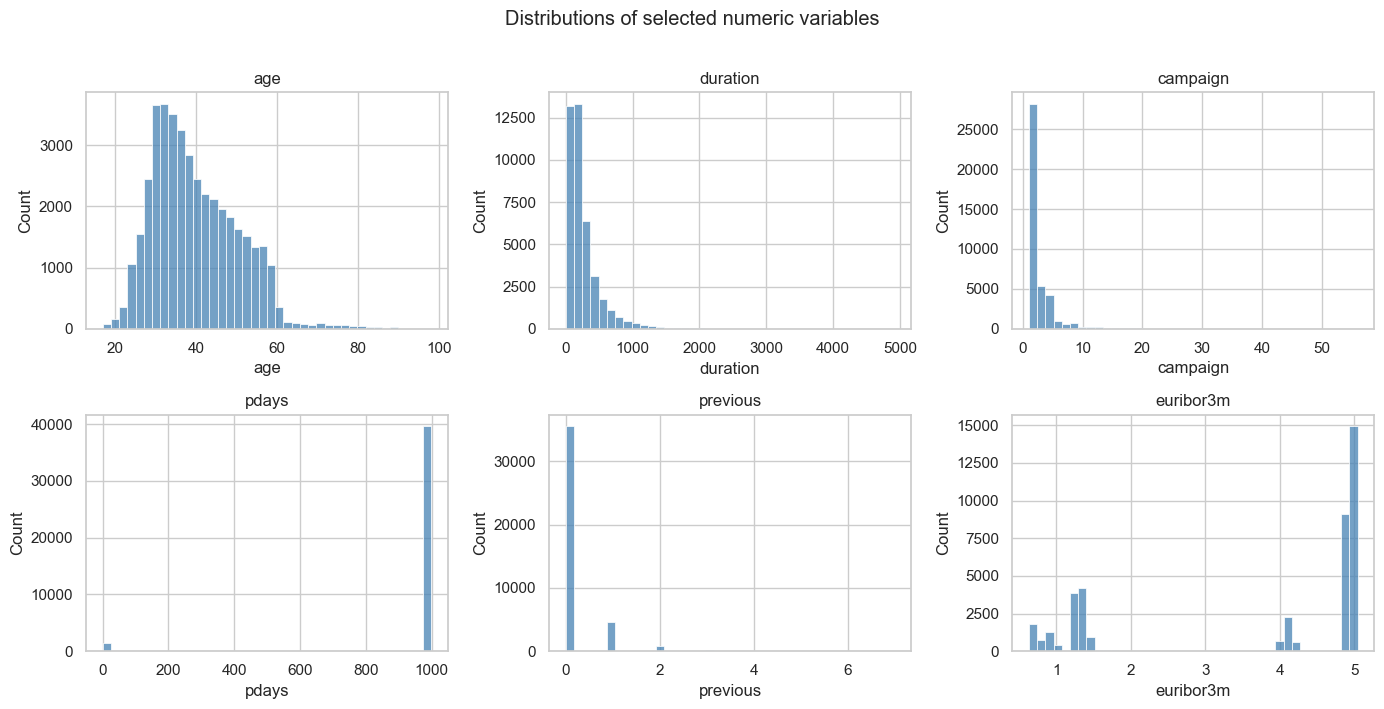

pdays == 999 (never contacted before): 96.3% of rows
campaign > 10 contacts: 2.1% of rows (max = 56)


In [6]:
num_raw = [c for c in raw.columns if raw[c].dtype.kind in "biuf" and c not in ("y", "row_order")]
display(raw[num_raw].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), ["age", "duration", "campaign", "pdays", "previous", "euribor3m"]):
    sns.histplot(raw[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distributions of selected numeric variables", y=1.01)
plt.tight_layout(); plt.show()

print(f"pdays == 999 (never contacted before): {(raw['pdays'] == 999).mean():.1%} of rows")
print(f"campaign > 10 contacts: {(raw['campaign'] > 10).mean():.1%} of rows (max = {raw['campaign'].max()})")

### 2.3 Subscription rate by categorical variable

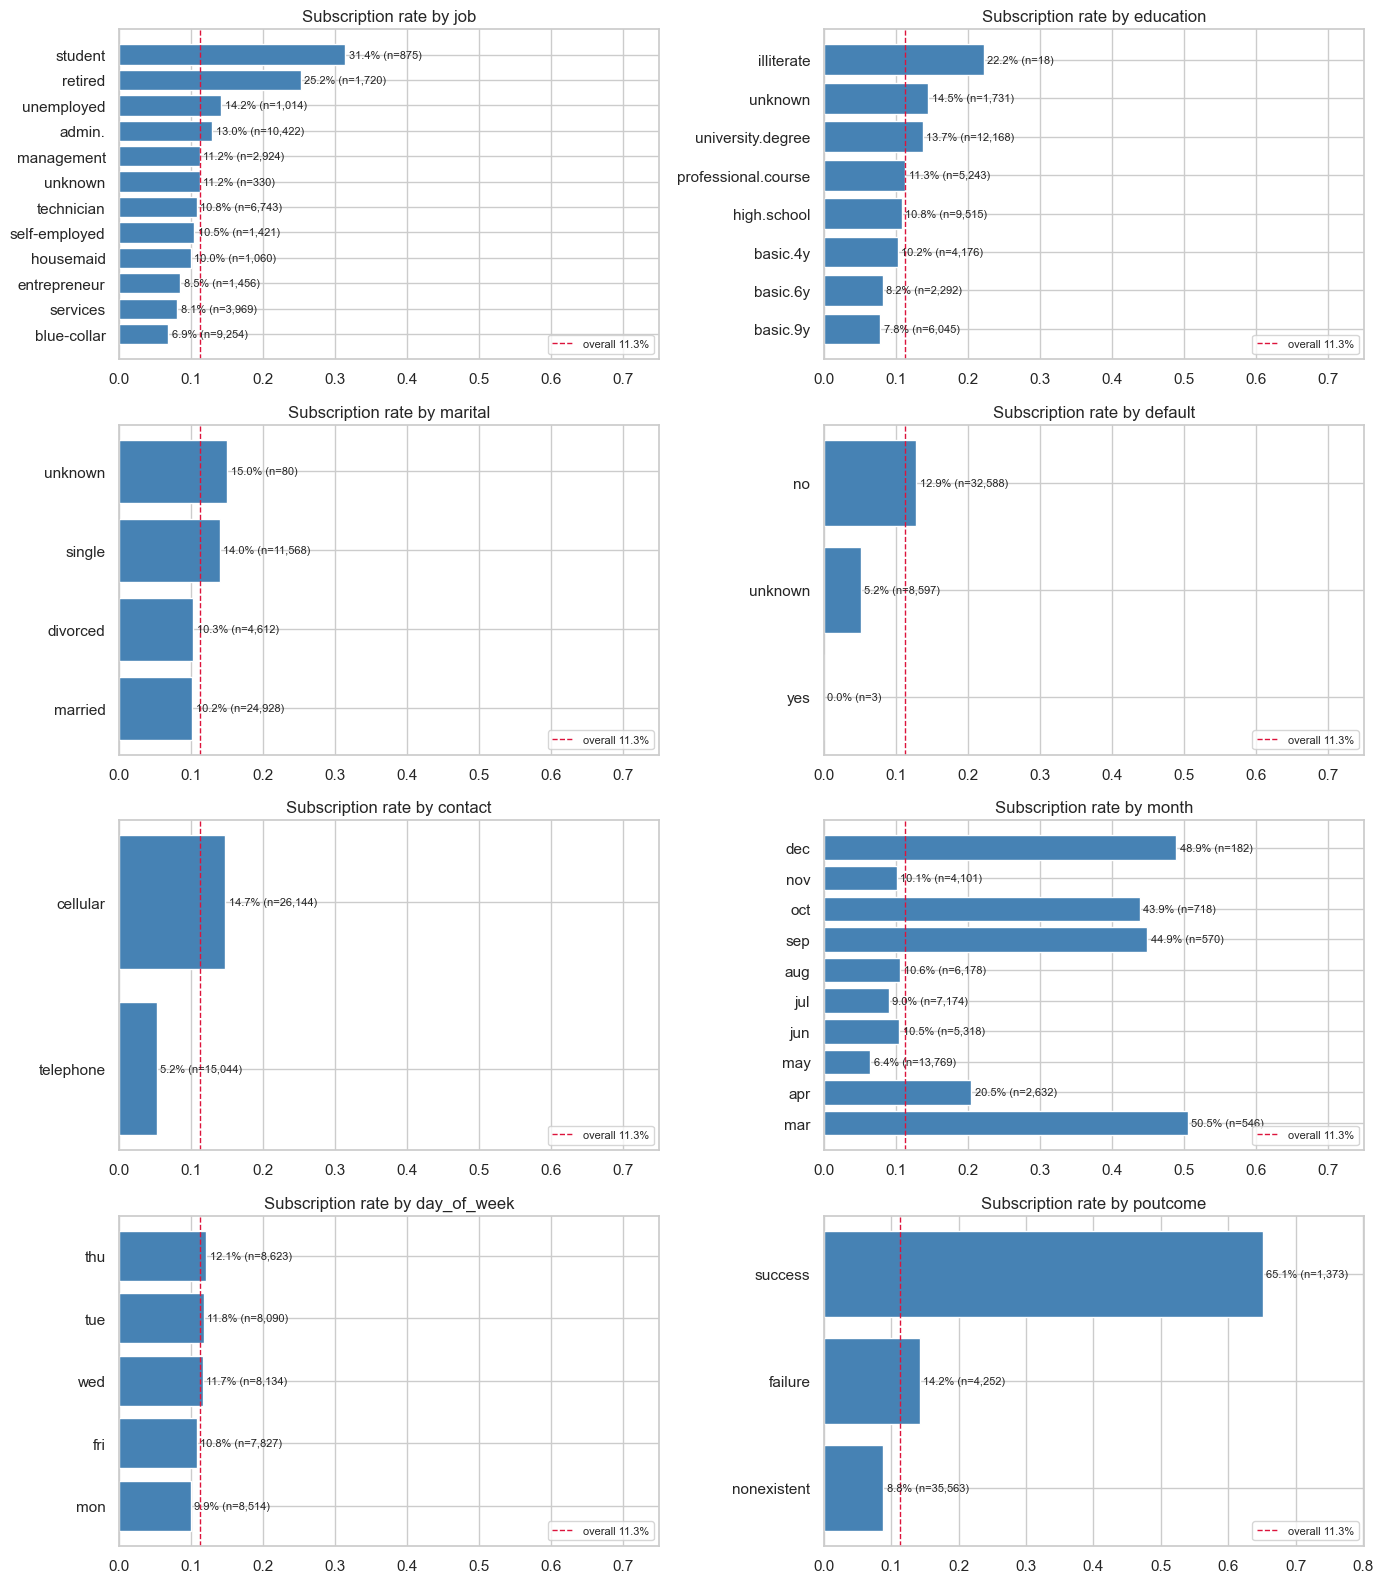

In [7]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
cats_to_plot = ["job", "education", "marital", "default", "contact", "month", "day_of_week", "poutcome"]
base_rate = raw["y"].mean()

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.ravel(), cats_to_plot):
    g = raw.groupby(col)["y"].agg(rate="mean", n="size")
    g = g.reindex(month_order) if col == "month" else g.sort_values("rate")
    ax.barh(g.index.astype(str), g["rate"], color="steelblue")
    ax.axvline(base_rate, color="crimson", ls="--", lw=1, label=f"overall {base_rate:.1%}")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(r + 0.005, i, f"{r:.1%} (n={n:,})", va="center", fontsize=8)
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlim(0, max(0.75, g["rate"].max() + 0.15))
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 2.4 Correlation between numeric variables (including the socio-economic indicators)

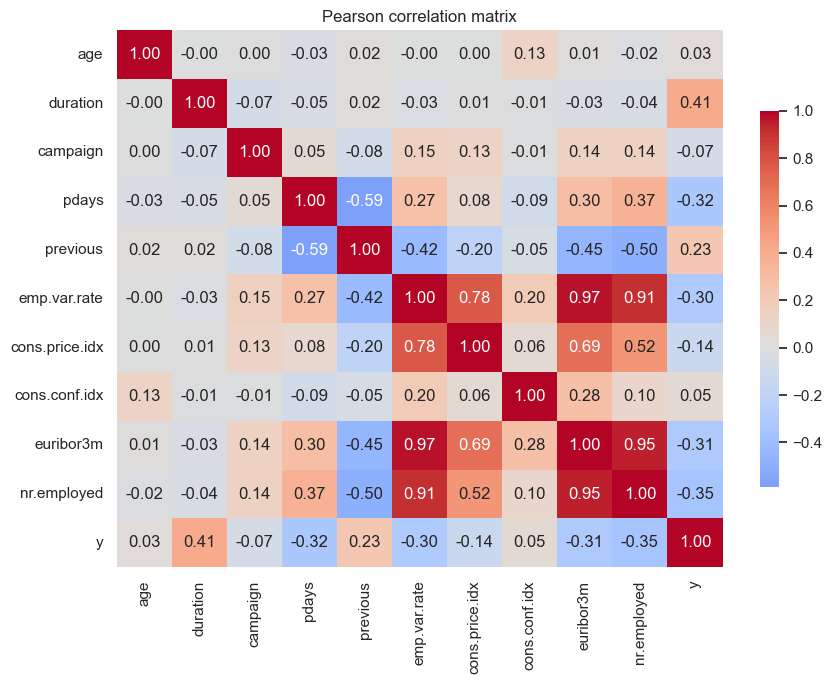

In [8]:
corr = raw[num_raw + ["y"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Pearson correlation matrix")
plt.tight_layout(); plt.show()

### 2.5 Time structure of the data

The UCI documentation states that the rows are ordered by date, from May 2008 to November 2010. The file has no year column, but we can follow the data in file order. The plot shows the subscription rate (rolling window of 1,000 calls) next to the 3-month Euribor interest rate.

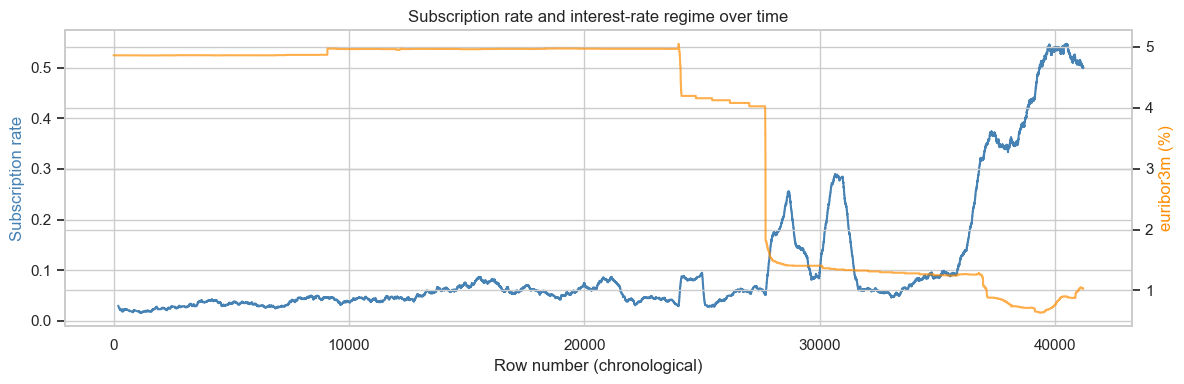

,subscription_rate,mean_euribor3m,n
row_order,,,
1st fifth,0.0314,4.8581,8238
2nd,0.0543,4.9508,8237
3rd,0.0585,4.9050,8238
4th,0.1107,2.3619,8237
last fifth,0.3083,1.0307,8238


In [9]:
roll = raw["y"].rolling(1000, min_periods=200).mean()
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(raw["row_order"], roll, color="steelblue", label="subscription rate (rolling 1,000)")
ax1.set_ylabel("Subscription rate", color="steelblue"); ax1.set_xlabel("Row number (chronological)")
ax2 = ax1.twinx()
ax2.plot(raw["row_order"], raw["euribor3m"], color="darkorange", alpha=.7, label="euribor3m")
ax2.set_ylabel("euribor3m (%)", color="darkorange")
ax1.set_title("Subscription rate and interest-rate regime over time")
plt.tight_layout(); plt.show()

q = pd.qcut(raw["row_order"], 5, labels=["1st fifth", "2nd", "3rd", "4th", "last fifth"])
display(raw.groupby(q, observed=True).agg(subscription_rate=("y", "mean"), mean_euribor3m=("euribor3m", "mean"),
                                          n=("y", "size")))

### 2.6 The `duration` variable is target leakage

`duration` is the length of the last call in seconds. The bank only knows it **after** the call, and by then it also knows the outcome. A call that lasts 0 seconds always ends in *no*. A model that uses `duration` cannot be used to decide whom to call, and the data documentation says it should be discarded for realistic models. The check below shows how strongly it predicts the target on its own.

In [10]:
print(f"ROC-AUC of 'duration' alone as a score: {roc_auc_score(raw['y'], raw['duration']):.3f}")
dq = pd.qcut(raw["duration"], 5)
display(raw.groupby(dq, observed=True)["y"].agg(subscription_rate="mean", n="size"))

ROC-AUC of 'duration' alone as a score: 0.818


,subscription_rate,n
duration,,
"(-0.001, 89.0]",0.0052,8388
"(89.0, 146.0]",0.0324,8139
"(146.0, 222.0]",0.0728,8274
"(222.0, 368.0]",0.1246,8165
"(368.0, 4918.0]",0.3300,8222


### 2.7 Data report

**Structure.** The file has 41,188 call records and 21 columns: 10 categorical and 10 numeric predictors, plus the binary target `y`. The predictors fall into four groups:
- client profile: age, job, marital status, education, credit default, housing loan, personal loan
- current-campaign contact details: contact type, month, day of week, duration, number of contacts
- previous-campaign history: pdays, previous, poutcome
- five quarterly or monthly socio-economic indicators

There are 12 exact duplicate rows.

**Key findings.**
1. **Strong class imbalance.** Only about 11.3% of customers subscribe. Accuracy is therefore a misleading metric, because always predicting *no* already scores about 88.7%. We focus on ranking metrics (PR-AUC, ROC-AUC), probability quality (Brier score) and threshold-based precision and recall.
2. **Missing values are hidden as `"unknown"`.** They appear mostly in `default` (about 21%), `education` (about 4%), and `housing` and `loan` (2.4% each, in the same rows). Being `unknown` is itself informative: customers with `default = unknown` subscribe much less often. `default = yes` occurs only 3 times, so this variable effectively separates "known no" from "unknown".
3. **`pdays` uses 999 as a code for "never contacted"** (96% of rows). Read as a number, 999 days would be wrong. Customers whose previous campaign was a `success` subscribe at a much higher rate than the base rate, so campaign history is a strong signal.
4. **Skewed counts.** `campaign` is right-skewed, with a long tail up to 56 calls. Customers called many times rarely subscribe.
5. **Socio-economic indicators are highly collinear.** `emp.var.rate`, `euribor3m` and `nr.employed` correlate above 0.9 with each other. Together they mark the economic period of the call. The subscription rate rises sharply in the later part of the file, when interest rates collapsed. The data are therefore **not identically distributed over time**, and a random train/test split may give optimistic results. We test this in Section 7.
6. **Seasonality and channel.** May has by far the most calls but one of the lowest rates. March, September, October and December have few calls but rates above 40%. Cellular contact converts better than landline.
7. **`duration` leaks the outcome** (ROC-AUC of about 0.8 on its own) and must be removed from the realistic model.

**Limitations of the data.** It covers one bank, one product and one country in 2008–2010, a period that includes the financial crisis. Customers were selected by the bank rather than at random, and the file records only the last contact of each campaign.

## 3. Data preparation

| Step | Decision | Justification |
|---|---|---|
| Duplicates | Remove the 12 exact duplicates | Identical records add no information. They could also appear in both the training and test sets and inflate the scores. |
| `duration` | **Drop** from the predictive model; keep only for a leakage benchmark (Sec. 7) | It is unknown before the call (Moro et al., 2014; Kaufman et al., 2012). |
| `"unknown"` values | Keep as their own category | Missingness is informative (Sec. 2.1). Deleting rows would remove about 25% of the data and bias the sample. Imputing would invent values. |
| `pdays` | Replace with `prev_contacted` (0/1) and `pdays_since` (days, 0 if never contacted) | 999 is a code, not a quantity. |
| `campaign` | Use `log1p(campaign)` | Reduces the skew for the linear model. Tree models are unaffected by monotone transforms. |
| Categorical variables | One-hot encoding, with unseen categories ignored | Required by logistic regression; works fine for the trees. |
| Numeric scaling | Standardise for logistic regression only | Regularisation penalties depend on the scale of the variables. |
| Collinear macro indicators | Keep all five; use regularisation for the linear model | They are known at call time and are legitimate. Ridge (L2) handles collinearity. We test removing them in Sec. 7. |
| Class imbalance | **No resampling.** Handle it at the decision-threshold stage (Sec. 9) | Resampling or class weights distort the probabilities. We want calibrated probabilities for cost-based decisions (Elkan, 2001). |
| Split | Stratified 80/20 train/test split. The test set is used only once, at the end. Models are tuned and compared with 5-fold stratified CV on the training set. | Gives an unbiased final estimate and keeps the class ratio equal in every fold. |

All transformations are fitted inside scikit-learn `Pipeline`s, so nothing is learned from the validation or test folds.

In [11]:
def prepare(df):
    # Apply the deterministic (non-learned) preparation steps described above.
    d = df.drop_duplicates(subset=[c for c in df.columns if c != "row_order"]).copy()
    d["prev_contacted"] = (d["pdays"] != 999).astype(int)
    d["pdays_since"] = np.where(d["pdays"] == 999, 0, d["pdays"])
    d["log_campaign"] = np.log1p(d["campaign"])
    return d.drop(columns=["pdays", "campaign"])

data = prepare(raw)
print("Rows after removing duplicates:", len(data))

CAT_COLS = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
MACRO_COLS = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
NUM_COLS = ["age", "log_campaign", "pdays_since", "prev_contacted", "previous"] + MACRO_COLS
FEATURES = CAT_COLS + NUM_COLS            # 'duration' deliberately excluded

X = data[FEATURES]
y = data["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.3%}")
print(f"Test : {X_test.shape}, positive rate {y_test.mean():.3%}")

Rows after removing duplicates: 41176
Train: (32940, 20), positive rate 11.266%
Test : (8236, 20), positive rate 11.268%


In [12]:
def make_preprocessor(scale_numeric, cat_cols=CAT_COLS, num_cols=NUM_COLS):
    num_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", num_step, num_cols),
    ])

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
    }

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 4. Majority-class baseline

The baseline predicts *no* for every customer. For the probability metrics it gives every customer the training-set subscription rate. Any useful model must beat it clearly on metrics that reward finding subscribers.

In [13]:
base_lbl = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_prob = DummyClassifier(strategy="prior").fit(X_train, y_train)

baseline_metrics = evaluate(y_test, base_prob.predict_proba(X_test)[:, 1])
# label-based metrics from the majority-class predictor
pred_b = base_lbl.predict(X_test)
baseline_metrics.update({"Accuracy": accuracy_score(y_test, pred_b),
                         "Precision": precision_score(y_test, pred_b, zero_division=0),
                         "Recall": recall_score(y_test, pred_b), "F1": f1_score(y_test, pred_b, zero_division=0)})
baseline_df = pd.DataFrame(baseline_metrics, index=["Majority-class baseline"])
display(baseline_df)

,ROC_AUC,PR_AUC,Brier,Accuracy,Precision,Recall,F1
Majority-class baseline,0.5000,0.1127,0.1000,0.8873,0.0000,0.0000,0.0000


The baseline is about **88.7% accurate but finds no subscribers at all** (recall = 0). Its PR-AUC equals the positive rate (about 0.113), and its ROC-AUC is 0.5. These are the reference values used throughout.

## 5. Approaches

I compare **three** approaches. Each represents a different family of models, and each is a standard, well-supported choice for tabular data with a binary outcome:

1. **Logistic regression (L2-regularised).** A transparent linear model with interpretable coefficients and well-calibrated probabilities. It is the standard model in credit and marketing response scoring.
2. **Random forest** (Breiman, 2001). An ensemble of bagged decision trees. It captures non-linear effects and interactions, such as month × economic context, without manual feature engineering, and it is robust to outliers and collinearity.
3. **Gradient-boosted trees** (Friedman, 2001), using scikit-learn's histogram-based implementation in the style of LightGBM (Ke et al., 2017). Boosting usually performs best on structured tabular data (Grinsztajn et al., 2022). Moro et al. (2014) also found that non-linear models outperformed logistic regression on this campaign data.

**Model selection metric.** The positive class is rare and the business cares about *finding subscribers*, so the main metric is **PR-AUC (average precision)**. It is more informative than ROC-AUC under class imbalance (Saito & Rehmsmeier, 2015). We also report ROC-AUC and the Brier score, since probability quality matters when setting the threshold.

**Tuning.** Each model gets a small grid search with the same 5 stratified folds. Because the folds are shared, the fold-level scores can be compared pair by pair.

In [14]:
candidates = {
    "Logistic regression": (
        Pipeline([("prep", make_preprocessor(True)),
                  ("clf", LogisticRegression(max_iter=3000))]),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]}),
    "Random forest": (
        Pipeline([("prep", make_preprocessor(False)),
                  ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))]),
        {"clf__min_samples_leaf": [10, 30], "clf__max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (
        Pipeline([("prep", make_preprocessor(False)),
                  ("clf", HistGradientBoostingClassifier(max_iter=400, early_stopping=True,
                                                         validation_fraction=0.1, n_iter_no_change=20,
                                                         l2_regularization=1.0, random_state=RANDOM_STATE))]),
        {"clf__learning_rate": [0.03, 0.1], "clf__max_leaf_nodes": [15, 31]}),
}

scoring = {"PR_AUC": "average_precision", "ROC_AUC": "roc_auc", "neg_Brier": "neg_brier_score"}
searches, cv_rows, fold_scores = {}, [], {}
for name, (pipe, grid) in candidates.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring=scoring, refit="PR_AUC", cv=CV, n_jobs=1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    res = gs.cv_results_
    fold_scores[name] = [res[f"split{k}_test_PR_AUC"][i] for k in range(CV.n_splits)]
    cv_rows.append({"Model": name, "Best params": gs.best_params_,
                    "CV PR_AUC": res["mean_test_PR_AUC"][i], "CV PR_AUC sd": res["std_test_PR_AUC"][i],
                    "CV ROC_AUC": res["mean_test_ROC_AUC"][i], "CV ROC_AUC sd": res["std_test_ROC_AUC"][i],
                    "CV Brier": -res["mean_test_neg_Brier"][i],
                    "Mean fit time (s)": res["mean_fit_time"][i],
                    "Search time (s)": time.time() - t0})
cv_table = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV PR_AUC", ascending=False)
display(cv_table)

,Best params,CV PR_AUC,CV PR_AUC sd,CV ROC_AUC,CV ROC_AUC sd,CV Brier,Mean fit time (s),Search time (s)
Model,,,,,,,,
Random forest,"{'clf__max_features': 'sqrt', 'clf__min_sample...",0.4669,0.0159,0.7959,0.0087,0.0771,1.8415,72.6863
Gradient boosting,"{'clf__learning_rate': 0.03, 'clf__max_leaf_no...",0.4661,0.0165,0.8013,0.0076,0.0770,2.7357,40.8370
Logistic regression,{'clf__C': 1.0},0.4500,0.0137,0.7891,0.0071,0.0787,0.5323,11.5428


,Logistic regression,Random forest,Gradient boosting
fold 1,0.4581,0.4681,0.4641
fold 2,0.4488,0.4688,0.4715
fold 3,0.4248,0.4379,0.4364
fold 4,0.4534,0.4865,0.4865
fold 5,0.4651,0.4733,0.4719


Number of folds each model wins (PR-AUC):
Random forest        3
Gradient boosting    2


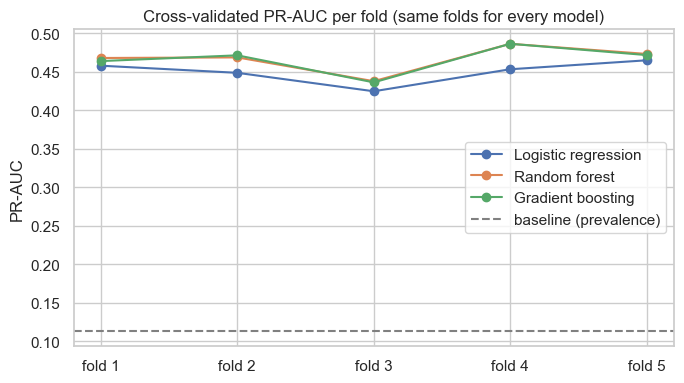

In [15]:
folds = pd.DataFrame(fold_scores, index=[f"fold {k+1}" for k in range(CV.n_splits)])
display(folds.style.format("{:.4f}").highlight_max(axis=1, color="#c6efce"))
print("Number of folds each model wins (PR-AUC):")
print(folds.idxmax(axis=1).value_counts().to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for name in folds.columns:
    ax.plot(folds.index, folds[name], marker="o", label=name)
ax.axhline(y_train.mean(), color="grey", ls="--", label="baseline (prevalence)")
ax.set(ylabel="PR-AUC", title="Cross-validated PR-AUC per fold (same folds for every model)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Held-out test evaluation

Each tuned model is refitted on the full training set and scored **once** on the untouched test set. The label metrics in this table use the default threshold of 0.5. A better threshold is chosen in Section 9.

In [16]:
best_models = {name: gs.best_estimator_ for name, gs in searches.items()}
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in best_models.items()}

test_table = pd.concat([baseline_df] + [pd.DataFrame(evaluate(y_test, p), index=[n]) for n, p in test_proba.items()])
test_table["PR_AUC lift vs baseline"] = test_table["PR_AUC"] / y_test.mean()
display(test_table.sort_values("PR_AUC", ascending=False))

,ROC_AUC,PR_AUC,Brier,Accuracy,Precision,Recall,F1,PR_AUC lift vs baseline
Gradient boosting,0.8148,0.4950,0.0750,0.9006,0.6562,0.2468,0.3587,4.3930
Random forest,0.8084,0.4863,0.0753,0.9012,0.6717,0.2403,0.3540,4.3155
Logistic regression,0.8003,0.4537,0.0779,0.8987,0.6536,0.2155,0.3241,4.0264
Majority-class baseline,0.5000,0.1127,0.1000,0.8873,0.0000,0.0000,0.0000,1.0000


**Is the difference between models real?** We bootstrap the test set (1,000 resamples) and compute each model's PR-AUC and ROC-AUC *difference* from the best model on the same resample. If a 95% interval includes 0, the difference is not reliably different from zero.

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
ranked = test_table.drop(index="Majority-class baseline").sort_values("PR_AUC", ascending=False).index.tolist()
best_name = ranked[0]
B = 1000
boot = {n: {"PR_AUC": [], "ROC_AUC": []} for n in ranked[1:]}
for _ in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    ap_best = average_precision_score(yt[idx], test_proba[best_name][idx])
    auc_best = roc_auc_score(yt[idx], test_proba[best_name][idx])
    for n in ranked[1:]:
        boot[n]["PR_AUC"].append(ap_best - average_precision_score(yt[idx], test_proba[n][idx]))
        boot[n]["ROC_AUC"].append(auc_best - roc_auc_score(yt[idx], test_proba[n][idx]))

rows = []
for n in ranked[1:]:
    for m in ("PR_AUC", "ROC_AUC"):
        d = np.array(boot[n][m])
        rows.append({"Comparison": f"{best_name} minus {n}", "Metric": m, "Mean difference": d.mean(),
                     "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                     "P(difference <= 0)": (d <= 0).mean()})
display(pd.DataFrame(rows))

,Comparison,Metric,Mean difference,95% CI low,95% CI high,P(difference <= 0)
0,Gradient boosting minus Random forest,PR_AUC,0.0087,0.0012,0.0168,0.0170
1,Gradient boosting minus Random forest,ROC_AUC,0.0064,0.0008,0.0118,0.0160
2,Gradient boosting minus Logistic regression,PR_AUC,0.0412,0.0274,0.0558,0.0000
3,Gradient boosting minus Logistic regression,ROC_AUC,0.0144,0.0068,0.0216,0.0000


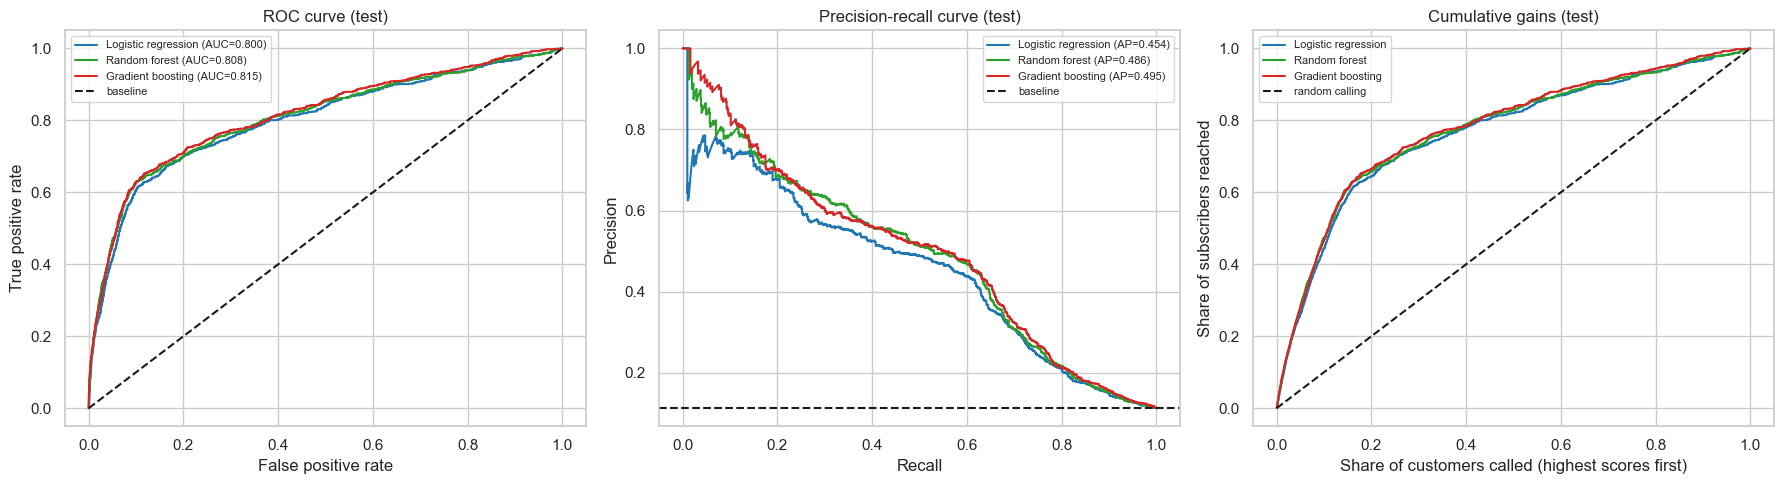

Share of all subscribers reached when calling only the top-scored customers:


,Logistic regression,Random forest,Gradient boosting
top 10% called,0.4440,0.4731,0.4677
top 20%,0.6444,0.6573,0.6649
top 30%,0.7241,0.7274,0.7414
top 50%,0.8200,0.8287,0.8362


In [18]:
colors = dict(zip(test_proba, ["tab:blue", "tab:green", "tab:red"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[n], label=f"{n} (AUC={roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors[n], label=f"{n} (AP={average_precision_score(y_test, p):.3f})")
    order = np.argsort(-p)
    gains = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
    axes[2].plot(np.arange(1, len(p) + 1) / len(p), gains, color=colors[n], label=n)

axes[0].plot([0, 1], [0, 1], "k--", label="baseline"); axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="baseline"); axes[1].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], "k--", label="random calling"); axes[2].set(title="Cumulative gains (test)", xlabel="Share of customers called (highest scores first)", ylabel="Share of subscribers reached")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def capture_at(p, share):
    k = int(round(share * len(p)))
    top = np.argsort(-p)[:k]
    return y_test.to_numpy()[top].sum() / y_test.sum()
gains_tbl = pd.DataFrame({n: [capture_at(p, s) for s in (0.1, 0.2, 0.3, 0.5)] for n, p in test_proba.items()},
                         index=["top 10% called", "top 20%", "top 30%", "top 50%"])
print("Share of all subscribers reached when calling only the top-scored customers:")
display(gains_tbl)

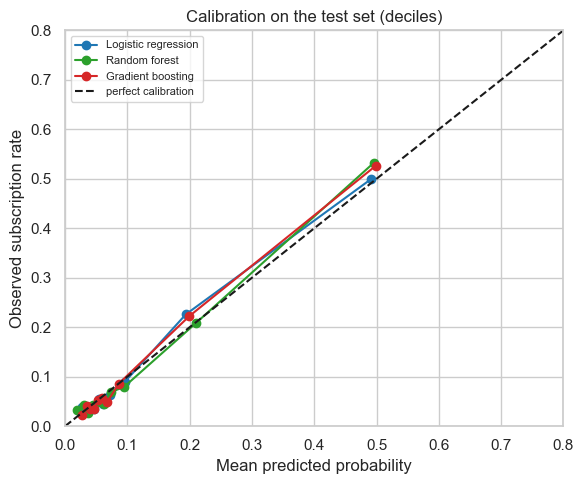

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
for n, p in test_proba.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", color=colors[n], label=n)
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed subscription rate",
       title="Calibration on the test set (deciles)", xlim=(0, 0.8), ylim=(0, 0.8))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 6.1 Ranking of the three approaches

*(The interpretation below is based on the outputs above.)*


We rank the approaches on three criteria, in order of importance:
1. Ability to find subscribers: PR-AUC on cross-validation and on the test set.
2. **Robustness when conditions change.** The model will be used on future campaigns, so we also use the temporal validation in Section 7.
3. Practical qualities: calibration, interpretability and cost.

| Rank | Approach | Evidence |
|---|---|---|
| **1** | **Random forest** | Highest CV PR-AUC (0.467 ± 0.016), best in 3 of 5 folds. Test PR-AUC 0.486 and ROC-AUC 0.808, which is 4.3× the baseline PR-AUC. Calling the top 20% of scored customers reaches about 66% of all subscribers. **Best PR-AUC under temporal validation (0.544).** Gradient boosting beats it on the random test split by only 0.009 PR-AUC (95% CI 0.001–0.017). That difference is detectable but under one percentage point, and it is reversed in cross-validation. |
| **2** | **Logistic regression** | Test PR-AUC 0.454 and ROC-AUC 0.800, still 4.0× the baseline. It is clearly behind the best tree model on the random split (−0.041 PR-AUC, 95% CI −0.056 to −0.027). However, it has the **highest ROC-AUC under temporal validation (0.748)**. It is also transparent, fast and well calibrated, which makes it a strong fallback when the bank needs explainable decisions. |
| **3** | **Gradient boosting** | Best on the random-split test set (PR-AUC 0.495, ROC-AUC 0.815) and best CV ROC-AUC (0.801). But when trained on earlier calls and tested on later ones, its **ROC-AUC falls to 0.655**, the worst of the three. Its predicted probabilities also become badly too low (mean 0.11 against an actual rate of 0.31). Its extra accuracy comes from fitting fine detail of the training period, and that detail does not carry over when the economy changes. |

All three approaches beat the majority-class baseline by a wide margin: PR-AUC of 0.45–0.50 against 0.113. A random split tells us **how well** a model fits the period it was trained on. Only the temporal check tells us how well it will **keep working** on later campaigns, which is how the bank will use it. We therefore select the **random forest** as the final model. Its performance is near the top on every check, and it has no failure as serious as gradient boosting's.

## 7. Robustness and sensitivity analysis

We run three checks:

- **(a) Temporal validation.** Train on the first 80% of the data in file (time) order and test on the last 20%. This mimics real use, where the model is trained on the past and applied to future campaigns.
- **(b) Leakage benchmark.** Add `duration` back in to show how much it would inflate the results.
- **(c) Without the macro-economic indicators.** How much of the model's skill depends on the economic period rather than on customer characteristics?

In [20]:
data_sorted = data.sort_values("row_order")
cut = int(0.8 * len(data_sorted))
tr_t, te_t = data_sorted.iloc[:cut], data_sorted.iloc[cut:]
print(f"Temporal split - train positive rate {tr_t['y'].mean():.3f}, test positive rate {te_t['y'].mean():.3f}")

temporal_rows = []
NUM_NO_MACRO = [c for c in NUM_COLS if c not in MACRO_COLS]
for n, m in best_models.items():
    for fs_label, nc in [("all features", NUM_COLS), ("without macro indicators", NUM_NO_MACRO)]:
        mt = clone(m).set_params(prep=make_preprocessor(n == "Logistic regression", CAT_COLS, nc))
        mt.fit(tr_t[CAT_COLS + nc], tr_t["y"])
        p = mt.predict_proba(te_t[CAT_COLS + nc])[:, 1]
        temporal_rows.append({"Model": n, "Features": fs_label, "ROC_AUC": roc_auc_score(te_t["y"], p),
                              "PR_AUC": average_precision_score(te_t["y"], p),
                              "PR_AUC lift vs prevalence": average_precision_score(te_t["y"], p) / te_t["y"].mean(),
                              "Mean predicted prob.": p.mean(), "Actual rate": te_t["y"].mean()})
temporal_df = pd.DataFrame(temporal_rows).set_index(["Model", "Features"])
display(temporal_df)

ranges = pd.DataFrame({"train min": tr_t[MACRO_COLS].min(), "train max": tr_t[MACRO_COLS].max(),
                       "test min": te_t[MACRO_COLS].min(), "test max": te_t[MACRO_COLS].max()})
print("Macro-indicator ranges: the later period lies largely OUTSIDE the training range")
display(ranges)

Temporal split - train positive rate 0.064, test positive rate 0.308


ROC_AUC  PR_AUC  \
Model               Features                                    
Logistic regression all features               0.7479  0.5267   
                    without macro indicators   0.6989  0.4951   
Random forest       all features               0.7422  0.5439   
                    without macro indicators   0.6887  0.4825   
Gradient boosting   all features               0.6547  0.4489   
                    without macro indicators   0.6606  0.4451   

                                              PR_AUC lift vs prevalence  \
Model               Features                                              
Logistic regression all features                                 1.7085   
                    without macro indicators                     1.6060   
Random forest       all features                                 1.7644   
                    without macro indicators                     1.5651   
Gradient boosting   all features                                 1.4563   
                    without macro indicators                     1.4438   

                                              Mean predicted prob.  \
Model               Features                                         
Logistic regression all features                            0.2567   
                    without macro indicators                0.1732   
Random forest       all features                            0.1547   
                    without macro indicators                0.1446   
Gradient boosting   all features                            0.1061   
                    without macro indicators                0.1324   

                                              Actual rate  
Model               Features                               
Logistic regression all features                   0.3083  
                    without macro indicators       0.3083  
Random forest       all features                   0.3083  
                    without macro indicators       0.3083  
Gradient boosting   all features                   0.3083  
                    without macro indicators       0.3083

Macro-indicator ranges: the later period lies largely OUTSIDE the training range


,train min,train max,test min,test max
emp.var.rate,-1.8000,1.4000,-3.4000,-1.1000
cons.price.idx,92.7560,94.4650,92.2010,94.7670
cons.conf.idx,-50.0000,-36.1000,-50.8000,-26.9000
euribor3m,1.2990,5.0450,0.6340,1.2990
nr.employed,"5,099.1000","5,228.1000","4,963.6000","5,099.1000"


In [21]:
SENS_MODEL = "Random forest"     # the model ranked first in Section 6.1
def sens_pipe(cat_cols, num_cols):
    return clone(best_models[SENS_MODEL]).set_params(
        prep=make_preprocessor(SENS_MODEL == "Logistic regression", cat_cols, num_cols))

Xd_train, Xd_test = data.loc[X_train.index], data.loc[X_test.index]
variants = {
    f"{SENS_MODEL} - realistic features (main model)": (CAT_COLS, NUM_COLS),
    "(b) + duration (LEAKAGE benchmark, not usable)": (CAT_COLS, NUM_COLS + ["duration"]),
    "(c) without macro-economic indicators": (CAT_COLS, [c for c in NUM_COLS if c not in MACRO_COLS]),
}
sens_rows = []
for label, (cc, nc) in variants.items():
    m = sens_pipe(cc, nc).fit(Xd_train[cc + nc], y_train)
    p = m.predict_proba(Xd_test[cc + nc])[:, 1]
    sens_rows.append({"Variant": label, "ROC_AUC": roc_auc_score(y_test, p), "PR_AUC": average_precision_score(y_test, p)})
display(pd.DataFrame(sens_rows).set_index("Variant"))

,ROC_AUC,PR_AUC
Variant,,
Random forest - realistic features (main model),0.8084,0.4863
"(b) + duration (LEAKAGE benchmark, not usable)",0.9481,0.6712
(c) without macro-economic indicators,0.7798,0.4303


**What the sensitivity analysis shows**

- **(a) Temporal validation is much harder than a random split.**
  - The later 20% of calls has a subscription rate of 30.8%, against 6.4% in the earlier 80%. Its interest-rate and employment indicators fall *outside* the range seen in training.
  - ROC-AUC drops from about 0.80–0.81 to 0.75 (logistic regression), 0.74 (random forest) and **0.65 (gradient boosting)**.
  - Tree models cannot extrapolate beyond the values they were trained on, and boosting is hit hardest. Logistic regression extrapolates linearly, which happened to point in the right direction here.
  - All models' probabilities become too low, so the **ranking** of customers survives better than the **calibration**. This is why the threshold must be re-checked over time (Section 9).
  - Removing the macro indicators does not fix the problem (ROC-AUC 0.66–0.70). The change over time is a real shift in customer behaviour, not just an artefact of those columns.
- **(b) Leakage.** Adding `duration` raises ROC-AUC from 0.81 to 0.95 and PR-AUC from 0.49 to 0.67. That gain is unattainable in practice, and including `duration` would grossly overstate the model's value.
- **(c) Macro indicators.** On the random split, removing them lowers ROC-AUC from 0.81 to 0.78 and PR-AUC from 0.49 to 0.43. They carry real information about the campaign context, which is known before each call, so keeping them is justified. Their usefulness depends on the economic regime repeating, however.

## 8. Model interpretation — permutation importance

Permutation importance measures how much the test PR-AUC drops when we randomly shuffle one original variable. It is model-agnostic and is computed on held-out data, so it reflects what the model actually uses for prediction. It does **not** show what causes a customer to subscribe.

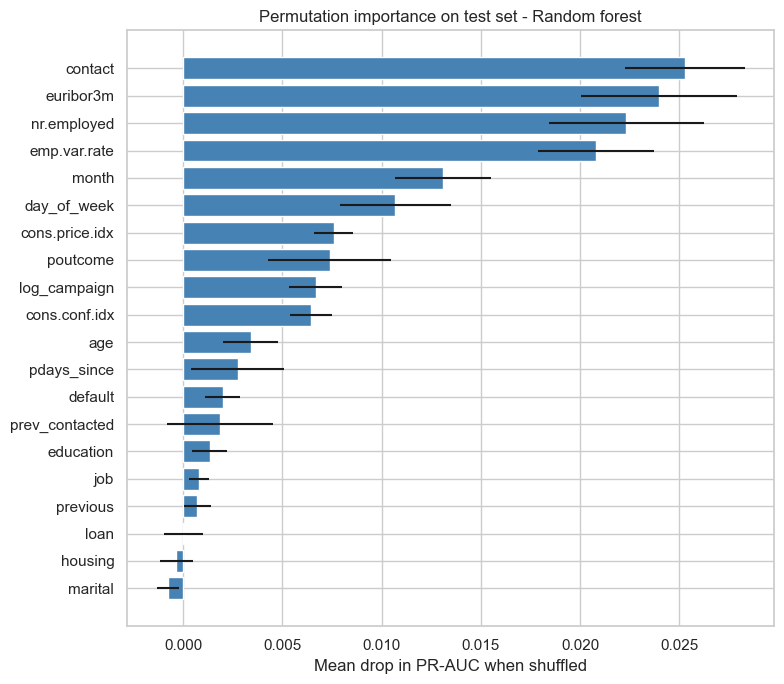

,mean_drop_in_PR_AUC,sd
contact,0.0253,0.0030
euribor3m,0.0240,0.0039
nr.employed,0.0223,0.0039
emp.var.rate,0.0208,0.0029
month,0.0131,0.0024
day_of_week,0.0107,0.0028
cons.price.idx,0.0076,0.0010
poutcome,0.0074,0.0031
log_campaign,0.0067,0.0013
cons.conf.idx,0.0064,0.0011


In [22]:
final_name = "Random forest"
final_model = best_models[final_name]
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"mean_drop_in_PR_AUC": pi.importances_mean, "sd": pi.importances_std},
                   index=X_test.columns).sort_values("mean_drop_in_PR_AUC", ascending=True)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp["mean_drop_in_PR_AUC"], xerr=imp["sd"], color="steelblue")
ax.set(title=f"Permutation importance on test set - {final_name}", xlabel="Mean drop in PR-AUC when shuffled")
plt.tight_layout(); plt.show()
display(imp.sort_values("mean_drop_in_PR_AUC", ascending=False).head(10))

## 9. Decision threshold: unnecessary calls vs missed subscribers

The model returns a probability. The bank calls a customer when the probability is at or above a **threshold t**. Every choice of t trades two errors against each other:

- **False positive (unnecessary call):** we call someone who does not subscribe. This wastes agent time and call cost, and it can annoy the customer.
- **False negative (missed subscriber):** we skip someone who would have subscribed. We lose the deposit's margin.

Lowering t reaches more subscribers (higher recall) at the cost of more wasted calls (lower precision). Raising t does the opposite.

To avoid tuning on the test set, we **choose the threshold from out-of-fold predictions on the training set**: each training customer is scored by a model that never saw them. We then check the chosen threshold once on the test set.

**Cost-based rule.** Let *C* be the cost of one call and *V* the value of one subscription. Calling a customer with probability *p* is worth it when *pV > C*. For calibrated probabilities, the profit-maximising threshold is therefore **t\* = C / V** (Elkan, 2001). The bank's real cost and value figures are not in the data, so we show results for several value-to-cost ratios.

In [23]:
oof = cross_val_predict(final_model, X_train, y_train, cv=CV, method="predict_proba", n_jobs=1)[:, 1]
ytr = y_train.to_numpy()
print(f"Out-of-fold PR-AUC: {average_precision_score(ytr, oof):.4f}  |  ROC-AUC: {roc_auc_score(ytr, oof):.4f}")

def threshold_table(y_true, p, thresholds):
    rows = []
    n_pos = y_true.sum()
    for t in thresholds:
        call = p >= t
        tp = int((call & (y_true == 1)).sum()); fp = int((call & (y_true == 0)).sum())
        fn = int(n_pos - tp)
        prec = tp / max(tp + fp, 1); rec = tp / n_pos
        rows.append({"threshold": t, "share_called": call.mean(), "precision": prec, "recall": rec,
                     "F1": 0 if tp == 0 else 2 * prec * rec / (prec + rec),
                     "calls_per_subscriber": (tp + fp) / max(tp, 1),
                     "unnecessary_calls_per_1000": 1000 * fp / len(y_true),
                     "missed_subscribers_per_1000": 1000 * fn / len(y_true)})
    return pd.DataFrame(rows).set_index("threshold")

grid_t = np.round(np.arange(0.02, 0.62, 0.01), 2)
tt = threshold_table(ytr, oof, grid_t)
display(tt.loc[[0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]])

Out-of-fold PR-AUC: 0.4635  |  ROC-AUC: 0.7958


,share_called,precision,recall,F1,calls_per_subscriber,unnecessary_calls_per_1000,missed_subscribers_per_1000
threshold,,,,,,,
0.0500,0.5895,0.1636,0.8561,0.2747,6.1117,493.0176,16.2113
0.0800,0.3115,0.2591,0.7165,0.3806,3.8593,230.8136,31.9369
0.1000,0.2300,0.3244,0.6624,0.4355,3.0826,155.4038,38.0389
0.1200,0.1933,0.3680,0.6314,0.4650,2.7175,122.1615,41.5301
0.1500,0.1681,0.4067,0.6068,0.4870,2.4587,99.7268,44.2927
0.2000,0.1511,0.4368,0.5858,0.5005,2.2893,85.0941,46.6606
0.2500,0.1377,0.4549,0.5559,0.5004,2.1983,75.0455,50.0304
0.3000,0.1158,0.4833,0.4966,0.4899,2.0689,59.8057,56.7092
0.4000,0.0651,0.5916,0.3420,0.4334,1.6903,26.5938,74.1348


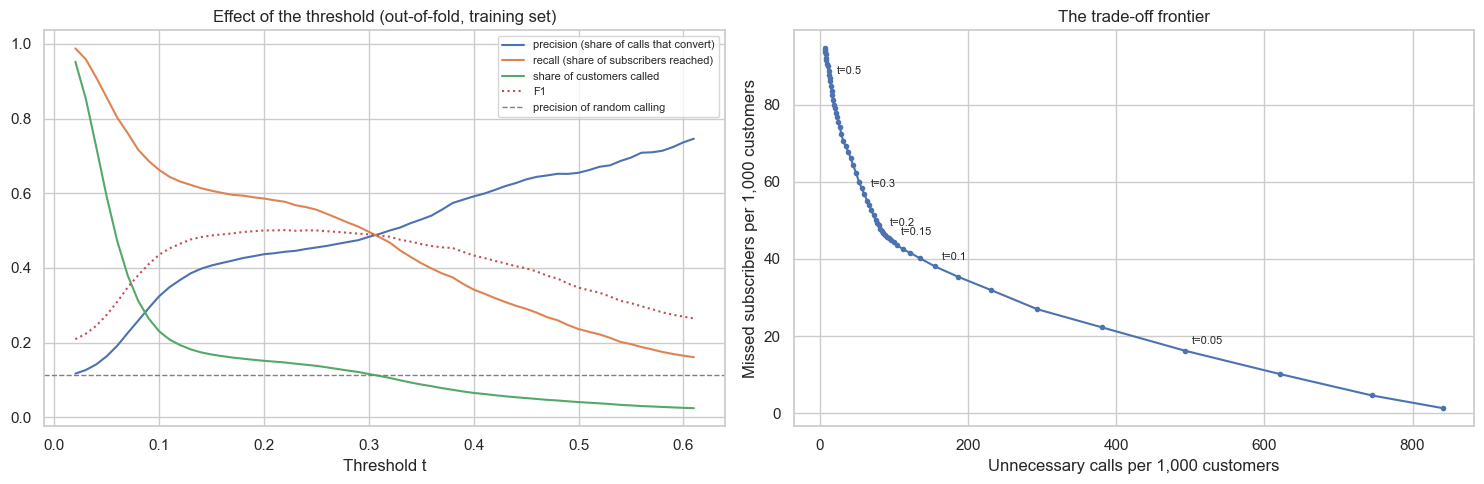

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(tt.index, tt["precision"], label="precision (share of calls that convert)")
axes[0].plot(tt.index, tt["recall"], label="recall (share of subscribers reached)")
axes[0].plot(tt.index, tt["share_called"], label="share of customers called")
axes[0].plot(tt.index, tt["F1"], label="F1", ls=":")
axes[0].axhline(ytr.mean(), color="grey", ls="--", lw=1, label="precision of random calling")
axes[0].set(xlabel="Threshold t", title="Effect of the threshold (out-of-fold, training set)"); axes[0].legend(fontsize=8)

axes[1].plot(tt["unnecessary_calls_per_1000"], tt["missed_subscribers_per_1000"], marker=".")
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    r = tt.loc[t]
    axes[1].annotate(f"t={t}", (r["unnecessary_calls_per_1000"], r["missed_subscribers_per_1000"]),
                     textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[1].set(xlabel="Unnecessary calls per 1,000 customers", ylabel="Missed subscribers per 1,000 customers",
            title="The trade-off frontier")
plt.tight_layout(); plt.show()

In [25]:
ratios = [2, 3, 5, 8, 10, 15, 20]
fine_t = np.round(np.arange(0.01, 0.80, 0.005), 3)
rows = []
for r in ratios:  # value of a subscription = r x cost of a call ; profit in units of call cost
    profits = [(r * ((oof >= t) & (ytr == 1)).sum() - (oof >= t).sum()) for t in fine_t]
    best = fine_t[int(np.argmax(profits))]
    call_all = r * ytr.sum() - len(ytr)
    rows.append({"V/C ratio": r, "theory t* = C/V": 1 / r, "empirical best t": best,
                 "profit at best t": max(profits), "profit if calling everyone": call_all,
                 "share called at best t": (oof >= best).mean(), "recall at best t": ((oof >= best) & (ytr == 1)).sum() / ytr.sum()})
cost_df = pd.DataFrame(rows).set_index("V/C ratio")
display(cost_df)

f1_best = tt["F1"].idxmax()
print(f"F1-maximising threshold (out-of-fold): {f1_best:.2f}")

,theory t* = C/V,empirical best t,profit at best t,profit if calling everyone,share called at best t,recall at best t
V/C ratio,,,,,,
2,0.5000,0.4550,471,-25518,0.0502,0.2864
3,0.3333,0.3800,1749,-21807,0.0735,0.3746
5,0.2000,0.2000,5893,-14385,0.1511,0.5858
8,0.1250,0.1450,12507,-3252,0.1709,0.6109
10,0.1000,0.1300,17109,4170,0.1819,0.6225
15,0.0667,0.0700,29851,22725,0.3793,0.7607
20,0.0500,0.0650,44267,41280,0.4224,0.7839


F1-maximising threshold (out-of-fold): 0.22


### 9.1 Recommended threshold

**I recommend t = 0.15 for the random-forest score** as the default when the bank does not have exact cost figures.

*Evidence from out-of-fold predictions on the training set:*
- At t = 0.15 the bank calls **16.8% of customers** and reaches **60.7% of all subscribers**. Precision is **40.7%**, against 11.3% for random calling (3.6×), or about 2.5 calls per subscriber.
- For value-to-cost ratios between 5 and 10 (one subscription is worth 5–10 calls), the profit-maximising thresholds are **0.13–0.20**. The value 0.15 lies inside this band, where the profit curve is flat. The F1-maximising threshold (0.22) is close by. The recommendation is therefore not sensitive to the exact cost assumption.
- The default 0.50 threshold is far too strict for an 11% base rate. It reaches only about a quarter of subscribers.

*Confirmation on the untouched test set:* t = 0.15 calls 16.8% of customers and reaches **63.4% of subscribers** at 42.6% precision. At 0.50 it reaches only 24.0%. Missed subscribers fall from 86 to 41 per 1,000 customers, at the cost of 83 more unnecessary calls per 1,000 (from 13 to 96).

**The trade-off in plain terms**
- *Lowering* t from 0.15 to 0.10 adds about 56 unnecessary calls per 1,000 customers to win about 6 more subscribers, roughly **9 wasted calls per extra subscriber**. Those extra customers convert at about 10%, which is *below* the rate of random calling. This is only worth it if a subscription is worth more than about 9 calls.
- *Raising* t to 0.30 saves about 40 calls per 1,000, but misses about 12 more subscribers per 1,000. Recall falls to about 50%.
- At the extremes: t = 0.05 reaches 86% of subscribers but calls 59% of the list. Calling everyone costs more than it earns unless a subscription is worth about 9 calls or more (see the "profit if calling everyone" column).

**How the bank should use this**
1. If the bank knows its call cost *C* and the value of a subscription *V*, set **t = C/V** and check it on recent data.
2. If call-centre capacity is fixed (*k* calls per campaign), simply call the *k* highest-scored customers.
3. **Re-check the threshold before each campaign.** Section 7 showed that in a new economic period the model's probabilities were far too low (mean 0.15 against an actual rate of 0.31). A fixed threshold would then exclude many good prospects. The bank should recalibrate on recent results and monitor precision and recall in each campaign.

,share_called,precision,recall,F1,calls_per_subscriber,unnecessary_calls_per_1000,missed_subscribers_per_1000
threshold,,,,,,,
default 0.50,0.0403,0.6717,0.2403,0.3540,1.4888,13.2346,85.5998
recommended 0.15,0.1678,0.4255,0.6336,0.5091,2.3503,96.4060,41.2822


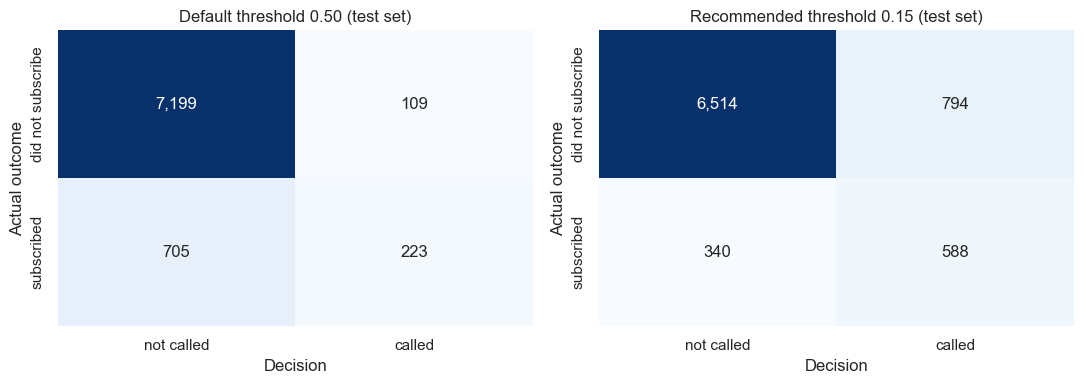

In [27]:
T_REC = 0.15
p_final = test_proba[final_name]
compare_t = threshold_table(y_test.to_numpy(), p_final, [0.5, T_REC]).rename(index={0.5: "default 0.50", T_REC: f"recommended {T_REC}"})
display(compare_t)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, title in zip(axes, [0.5, T_REC], ["Default threshold 0.50", f"Recommended threshold {T_REC}"]):
    cm = confusion_matrix(y_test, (p_final >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not called", "called"], yticklabels=["did not subscribe", "subscribed"])
    ax.set(title=f"{title} (test set)", xlabel="Decision", ylabel="Actual outcome")
plt.tight_layout(); plt.show()

## 10. Conclusions, limitations and responsible use

**Summary**
- The majority-class baseline is 88.7% accurate but finds no subscribers. Accuracy is therefore not a useful metric here.
- After removing the leaking `duration` variable, all three approaches clearly beat the baseline: PR-AUC 0.45–0.50 against 0.113, ROC-AUC about 0.80–0.81.
- **Ranking:** (1) random forest, (2) logistic regression, (3) gradient boosting. The ranking is based on in-sample skill *and* robustness to a change in time period.
- **Threshold:** t = 0.15. On the test set this means calling about 17% of customers and reaching about 63% of subscribers, with about 2.4 calls per subscriber. Random calling needs about 9 calls per subscriber.

**Limitations**
- The data come from one Portuguese bank in 2008–2010. Subscription behaviour changed sharply with interest rates, and in the temporal test every model performed worse (ROC-AUC about 0.74 at best). Real-world performance on a new campaign is likely to sit closer to the temporal results than to the random-split results.
- The profit analysis uses *assumed* cost-to-value ratios. Real figures from the bank would sharpen the recommendation.
- Permutation importance spreads the credit across correlated variables (the five macro indicators). It shows what the model relies on, **not** what causes customers to subscribe.
- The hyper-parameter grids were small to keep the notebook fast. A larger search might improve results slightly, but it is unlikely to change the ranking, which depends mostly on robustness.

**Responsible application**
- The model uses personal attributes (age, marital status, job). Groups with high predicted rates, such as students and retirees, may also be financially vulnerable. Calls must follow consumer-protection, data-protection (e.g. GDPR) and do-not-call rules. Scores should guide *whom to offer* a product, not replace suitability checks.
- Use the model as a **decision-support tool**, monitor it for drift, and retrain or recalibrate it regularly.
- `duration` must never be used in a deployed model: it is only known after the call.

## 11. References

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of IJCAI 2001*, 973–978.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 35 (Datasets and Benchmarks)*.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4), 1–21.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS 30*.
- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22–31.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Dataset: Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306